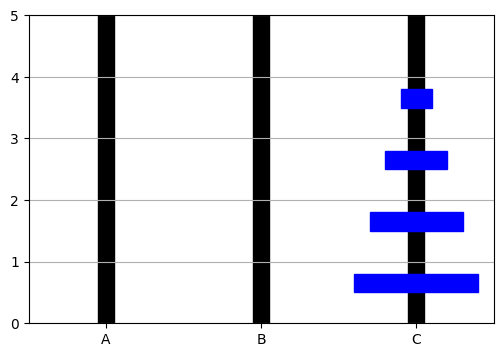

In [27]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.animation as animation

def inicializar_dados(num_discos):
    """ Inicializa a estrutura de dados para as torres e discos. """
    torres = {'A': [], 'B': [], 'C': []}
    for i in range(num_discos, 0, -1):
        torres['A'].append(i)  # Todos os discos começam na torre A
    return torres

def desenhar_torres(ax, num_discos):
    """ Desenha as torres (barras verticais). """
    for i in range(3):
        ax.add_patch(patches.Rectangle((i - 0.05, 0), 0.1, num_discos + 1, color="black"))

def inicializar_desenho(num_discos):
    """ Configura o ambiente gráfico do Matplotlib. """
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.set_xlim(-0.5, 2.5)
    ax.set_ylim(0, num_discos + 1)
    ax.set_xticks([0, 1, 2])
    ax.set_xticklabels(["A", "B", "C"])
    plt.grid(axis='y')

    desenhar_torres(ax, num_discos)

    # Criar discos visuais
    discos_graficos = {}
    for i in range(1, num_discos + 1):
        discos_graficos[i] = ax.add_patch(patches.Rectangle((-0.5, 0), i * 0.2, 0.3, color="blue"))

    return fig, ax, discos_graficos

def atualizar_grafico(discos_graficos, estado_torres):
    """ Atualiza a posição dos discos no gráfico conforme os movimentos. """
    for torre, pilha in estado_torres.items():
        for j, disco in enumerate(pilha):
            x = {'A': 0, 'B': 1, 'C': 2}[torre] - (disco * 0.1)
            y = j + 0.5
            discos_graficos[disco].set_xy((x, y))

def mover_disco(origem, destino, torres, movimentos):
    """ Move um disco de uma torre para outra e armazena o estado. """
    disco = torres[origem].pop()
    torres[destino].append(disco)
    movimentos.append({k: v[:] for k, v in torres.items()})  # Salva cópia do estado

def hanoi(n, origem, auxiliar, destino, torres, movimentos):
    """ Resolve recursivamente a Torre de Hanoi e registra os estados. """
    if n == 1:
        mover_disco(origem, destino, torres, movimentos)
        return
    hanoi(n - 1, origem, destino, auxiliar, torres, movimentos)
    mover_disco(origem, destino, torres, movimentos)
    hanoi(n - 1, auxiliar, origem, destino, torres, movimentos)

def animar(i):
    """ Atualiza o gráfico para cada quadro da animação. """
    atualizar_grafico(discos_graficos, movimentos[i])

def executar_hanoi(num_discos, nome_gif="hanoi.gif"):
    """ Configura e executa a animação da Torre de Hanoi, salvando como GIF. """
    global fig, ax, torres, discos_graficos, movimentos
    torres = inicializar_dados(num_discos)
    fig, ax, discos_graficos = inicializar_desenho(num_discos)

    movimentos = [{k: v[:] for k, v in torres.items()}]  # Estado inicial
    hanoi(num_discos, 'A', 'B', 'C', torres, movimentos)

    # Criar animação
    ani = animation.FuncAnimation(fig, animar, frames=len(movimentos), interval=500, repeat=False)

    # Salvar como GIF
    ani.save(nome_gif, writer="pillow", fps=2)

    plt.show()

# Definir número de discos e gerar GIF corretamente
num_discos = 4  # Pode ser alterado para testar com diferentes valores
executar_hanoi(num_discos, "torre_hanoi.gif")
